## 6.5 使用场景

### 6.5.1. 多轮对话

最基础的使用场景是多轮对话。前文示例已经实现了一个简单的多轮对话流程，这里不再展开。

### 6.5.2. 中断恢复

中断恢复需要结合 **`LangGraph`** 的中断机制理解，见下文。

### 6.5.3 失败后运行

要在失败后基于历史检查点恢复运行，需要满足以下条件：

1. 启用检查点存储器
   - 如果是 **`InMemorySaver`**，不要重建检查点存储器对象，否则历史检查点丢失，无法恢复
   - 如果希望跨进程、服务重启后仍可恢复，应使用基于 **`SQLite、Postgres`** 等持久化检查点后端的存储器
2. 再次运行时用 **`None`** 作为计算图的状态输入
3. 传递的配置信息应包含 **`thread_id`** 而不能包含 **`checkpoint_id`**

此时，**`LangGraph`** 会根据 **`thread_id`** 从 **`checkpointer`** 读取该会话的最新检查点，并从该检查点继续推进。

如果某个超步中有多个并行任务，其中一部分任务成功，另一部分任务失败，那么已经成功完成的任务结果会作为 **`pending_writes`** 被保存。恢复运行时，已经成功完成的任务不会重复执行。

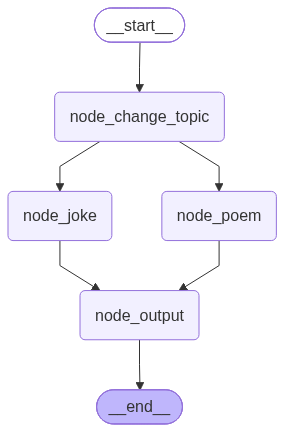

2026-10-17 19:27:28.389 | INFO     | __main__:node_change_topic:47 - topic_index:0
2026-10-17 19:27:28.391 | INFO     | __main__:node_joke:66 - node_joke正在执行
2026-10-17 19:27:28.392 | INFO     | __main__:node_poem:57 - node_poem正在执行


Exception: 人为抛异常

In [4]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

#1. 声明状态
class OverAllState(TypedDict):
    topic:str
    poem:str
    joke:str
    final_output:str

#1.1 输入状态
class InputState(TypedDict):
    topic:str

#1.2 输出状态
class OutputState(TypedDict):
    final_output:str

topics = ["布偶猫","狸花猫","金渐层"]
topic_index = 0
#2. 定义节点
def node_change_topic(state:InputState)->OverAllState:
    global topic_index
    logger.info("topic_index:{}",topic_index)
    sub_topic = topics[topic_index]
    topic_index += 1
    topic_index %= len(topics)

    return {
        "topic":f"{state['topic']}:{sub_topic}"
    }
#2.1 同一个超步的位置 成功运行的节点
def node_poem(state:OverAllState) -> OverAllState:
    logger.info("node_poem正在执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于{topic}主题的七言绝句")]).content
    return {
        "poem":poem
    }
import  time
#2.2 同一个超步的位置 运行失败的节点
def node_joke(state:OverAllState) -> OverAllState:
    logger.info("node_joke正在执行")
    topic = state["topic"]
    time.sleep(5)
    raise Exception("人为抛异常")
    joke = model.invoke([HumanMessage(f"写一首关于{topic}主题的笑话")]).content
    return {
        "joke":joke
    }

def node_output(state:OverAllState) -> OutputState:
    logger.info("node_output正在执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于{topic}的七言绝句:{poem}\n 笑话:{joke}\n"
    return {
        "final_output":final_output
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState,input_schema=InputState,output_schema=OutputState)

#3.1 添加节点
builder.add_node("node_change_topic",node_change_topic)
builder.add_node("node_poem",node_poem)
builder.add_node("node_joke",node_joke)
builder.add_node("node_output",node_output)

#3.2 添加边
builder.add_edge(START,"node_change_topic")
builder.add_edge("node_change_topic","node_poem")
builder.add_edge("node_change_topic","node_joke")
builder.add_edge("node_poem","node_output")
builder.add_edge("node_joke","node_output")
builder.add_edge("node_output",END)

# 定义并在编译时传递 Checkpointer
db_path = Path("/Users/skk/Developer/langgraph_learn/data/checkpoints.db")
db_path.parent.mkdir(parents=True, exist_ok=True)

with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    # 编译图
    graph = builder.compile(checkpointer=checkpointer)
    # 运行图
    display(graph)
    config = {
        "configurable":{
            "thread_id":"chapter03-05"
        }
    }

    res = graph.invoke({"topic":"猫"},config=config)
    print(res)

我们在 **`node_joke`** 中抛出异常，从而模拟计算图执行失败的场景。

如果恢复运行时 **`node_change_topic`** 没有再次执行，则最终结果仍然会使用第一次生成的主题，即 **`猫咪: 布偶猫`**。如果该节点被重新执行，则主题可能会变成 **`猫咪: 狸花猫`** 或 **`猫咪: 金渐层`**。

1. 查询历史检查点列表

In [8]:
with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    # 编译图
    graph = builder.compile(checkpointer=checkpointer)
    res = list(graph.get_state_history(config=config))
    rprint(res)

[
    StateSnapshot(
        values={'topic': '猫:布偶猫'},
        next=('node_poem', 'node_joke'),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c7-6dde-8001-f1595636b333'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-18T02:27:28.390493+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c3-6d2e-8000-3a185a2ffd4c'
            }
        },
        tasks=(
            PregelTask(
                id='4475cace-4229-9c73-46b4-47a87a03eaa3',
                name='node_poem',
                path=('__pregel_pull', 'node_poem'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'poem': '**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  \n玉尾轻摇春昼暖，  
\n梦追花蝶过回廊。'
                }
            ),
            PregelTask(
                id='d7dd27e8-eff4-36fb-62e3-2763e621e6c9',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error="Exception('人为抛异常')",
                interrupts=(),
                state=None,
                result=None
            )
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'topic': '猫'},
        next=('node_change_topic',),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c3-6d2e-8000-3a185a2ffd4c'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-18T02:27:28.388833+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c1-6880-bfff-2abba79fb99c'
            }
        },
        tasks=(
            PregelTask(
                id='0c3a0570-7947-e0c4-28d5-4ddde5b9c144',
                name='node_change_topic',
                path=('__pregel_pull', 'node_change_topic'),
                error=None,
                interrupts=(),
                state=None,
                result={'topic': '猫:布偶猫'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c1-6880-bfff-2abba79fb99c'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-18T02:27:28.387890+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='a1a2e392-52ab-db41-b656-254b21863864',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={'topic': '猫'}
            ),
        ),
        interrupts=()
    )
]

2. 继续运行

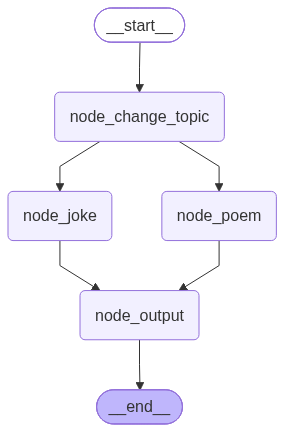

2026-10-17 19:46:31.161 | INFO     | __main__:node_joke:2 - node_joke 已执行
2026-10-17 19:46:36.141 | INFO     | __main__:node_output:76 - node_output正在执行


{
    'final_output': '关于猫:布偶猫的七言绝句:**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  
\n玉尾轻摇春昼暖，  \n梦追花蝶过回廊。\n 
笑话:布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”\n'
}

In [10]:
def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]

    joke = model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话")]).content

    return {
        "joke": joke
    }


builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("node_change_topic", node_change_topic)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)
builder.add_edge(START, "node_change_topic")
builder.add_edge("node_change_topic", "node_poem")
builder.add_edge("node_change_topic", "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)
with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    new_graph = builder.compile(checkpointer=checkpointer)

    from IPython.display import display
    display(new_graph)

    res = new_graph.invoke(None, config=config)
    rprint(res)

In [11]:
# 重新访问历史检查点列表
with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    # 编译图
    graph = builder.compile(checkpointer=checkpointer)
    res = list(graph.get_state_history(config=config))
    rprint(res)

[
    StateSnapshot(
        values={
            'topic': '猫:布偶猫',
            'poem': '**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  \n玉尾轻摇春昼暖，  
\n梦追花蝶过回廊。',
            'joke': '布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”',
            'final_output': '关于猫:布偶猫的七言绝句:**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  
\n玉尾轻摇春昼暖，  \n梦追花蝶过回廊。\n 
笑话:布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”\n'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9e2-2b98-6330-8003-92066220372c'
            }
        },
        metadata={'source': 'loop', 'step': 3, 'parents': {}},
        created_at='2026-10-18T02:46:36.142256+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9e2-2b93-6b8c-8002-98dd22bbdfc2'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'topic': '猫:布偶猫',
            'poem': '**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  \n玉尾轻摇春昼暖，  
\n梦追花蝶过回廊。',
            'joke': '布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”'
        },
        next=('node_output',),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9e2-2b93-6b8c-8002-98dd22bbdfc2'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-18T02:46:36.140416+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c7-6dde-8001-f1595636b333'
            }
        },
        tasks=(
            PregelTask(
                id='6703ddd5-2a81-e50c-a451-2189ca87a7df',
                name='node_output',
                path=('__pregel_pull', 'node_output'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'final_output': '关于猫:布偶猫的七言绝句:**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。
\n玉尾轻摇春昼暖，  \n梦追花蝶过回廊。\n 
笑话:布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”\n'
                }
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'topic': '猫:布偶猫'},
        next=('node_poem', 'node_joke'),
        config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c7-6dde-8001-f1595636b333'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-18T02:27:28.390493+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chapter03-05',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ca9b7-69c3-6d2e-8000-3a185a2ffd4c'
            }
        },
        tasks=(
            PregelTask(
                id='4475cace-4229-9c73-46b4-47a87a03eaa3',
                name='node_poem',
                path=('__pregel_pull', 'node_poem'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'poem': '**《布偶猫》**\n\n布偶慵依绣榻旁，  \n蓝眸如水映晴光。  \n玉尾轻摇春昼暖，  
\n梦追花蝶过回廊。'
                }
            ),
            PregelTask(
                id='d7dd27e8-eff4-36fb-62e3-2763e621e6c9',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error="Exception('人为抛异常')",
                interrupts=(),
                state=None,
                result={
                    'joke': 
'布偶猫为什么从不担心迟到？\n\n因为它一出门，大家都忍不住停下来：“哇，猫怎么能这么好看！”'
                }
            )
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'topic': '猫'},
  

这里需要注意两点：

1. 重新编译计算图时，仍然使用原来的 **`checkpointer`** 对象。
2. 恢复运行时，输入参数传入 **`None`**，并且配置中只传入 **`thread_id`**。

### 6.5.4 Time Travel
理解为检查点回溯。

所谓**检查点回溯**，是指基于某个历史检查点，重新执行后续流程，或者在该检查点基础上修改状态并创建新的执行分支。

**检查点回溯**有两种形式，根据是否更改历史状态区分：

- **`Replay`**：检查点重放，回到某个历史检查点，沿着原先的执行路径重新执行后续节点。
- **`Fork`**：检查点分叉，回到某个历史检查点，修改状态，从该位置创建一条新的执行分支。

#### 6.5.4.1. Replay


**`Replay`** 模式和失败恢复很接近，但二者的触发方式和语义不同。

- 失败恢复通常基于最新检查点继续运行，配置中只包含 **`thread_id`**，不包含 **`checkpoint_id`**。

- **`Replay`** 则是显式传入某个历史检查点的配置，配置中包含 **`checkpoint_id`**。**`LangGraph`** 会据此从该历史检查点开始重放后续步骤。因此结果可能会与原来不同。

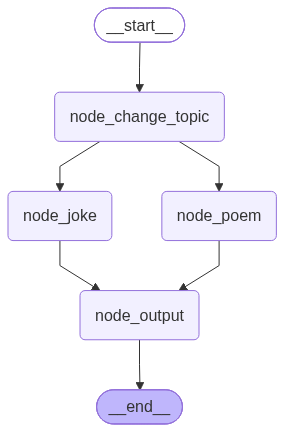

2026-10-17 20:19:57.004 | INFO     | __main__:node_change_topic:47 - topic_index:0
2026-10-17 20:19:57.006 | INFO     | __main__:node_joke:66 - node_joke正在执行
2026-10-17 20:19:57.008 | INFO     | __main__:node_poem:57 - node_poem正在执行
2026-10-17 20:22:23.034 | INFO     | __main__:node_output:76 - node_output正在执行


{'final_output': '关于猫:布偶猫的七言绝句:**《布偶猫》**\n\n布偶雪绒卧玉阶，  \n蓝眸如水映花开。  \n轻步悄追窗外蝶，  \n回身偎膝梦中乖。\n 笑话:布偶猫去面试，老板问：“你有什么特长？”\n\n它往沙发上一躺，眨眨眼说：“我特别会配合。”\n\n老板问：“怎么配合？”\n\n布偶猫打了个哈欠：“你工作，我负责把你的椅子坐热。”\n'}


In [15]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

#1. 声明状态
class OverAllState(TypedDict):
    topic:str
    poem:str
    joke:str
    final_output:str

#1.1 输入状态
class InputState(TypedDict):
    topic:str

#1.2 输出状态
class OutputState(TypedDict):
    final_output:str

topics = ["布偶猫","狸花猫","金渐层"]
topic_index = 0
#2. 定义节点
def node_change_topic(state:InputState)->OverAllState:
    global topic_index
    logger.info("topic_index:{}",topic_index)
    sub_topic = topics[topic_index]
    topic_index += 1
    topic_index %= len(topics)

    return {
        "topic":f"{state['topic']}:{sub_topic}"
    }
#2.1 同一个超步的位置 成功运行的节点
def node_poem(state:OverAllState) -> OverAllState:
    logger.info("node_poem正在执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于{topic}主题的七言绝句")]).content
    return {
        "poem":poem
    }
import  time
#2.2 同一个超步的位置 运行失败的节点
def node_joke(state:OverAllState) -> OverAllState:
    logger.info("node_joke正在执行")
    topic = state["topic"]
    #time.sleep(5)
    #raise Exception("人为抛异常")
    joke = model.invoke([HumanMessage(f"写一首关于{topic}主题的笑话")]).content
    return {
        "joke":joke
    }

def node_output(state:OverAllState) -> OutputState:
    logger.info("node_output正在执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于{topic}的七言绝句:{poem}\n 笑话:{joke}\n"
    return {
        "final_output":final_output
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState,input_schema=InputState,output_schema=OutputState)

#3.1 添加节点
builder.add_node("node_change_topic",node_change_topic)
builder.add_node("node_poem",node_poem)
builder.add_node("node_joke",node_joke)
builder.add_node("node_output",node_output)

#3.2 添加边
builder.add_edge(START,"node_change_topic")
builder.add_edge("node_change_topic","node_poem")
builder.add_edge("node_change_topic","node_joke")
builder.add_edge("node_poem","node_output")
builder.add_edge("node_joke","node_output")
builder.add_edge("node_output",END)

# 定义并在编译时传递 Checkpointer
db_path = Path("/Users/skk/Developer/langgraph_learn/data/checkpoints.db")
db_path.parent.mkdir(parents=True, exist_ok=True)

with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    # 编译图
    graph = builder.compile(checkpointer=checkpointer)
    # 运行图
    display(graph)
    config = {
        "configurable":{
            "thread_id":"chapter03-08"
        }
    }

    res = graph.invoke({"topic":"猫"},config=config)
    print(res)

获取检查点列表

In [16]:
with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    #5. 第一次使用PostgresSaver作为检查点 需要调用方法 setup()
    #checkpointer.setup()
    graph = builder.compile(checkpointer=checkpointer)

    config = {
        "configurable":{
            "thread_id":"chapter03-08"
        }
    }
    # 获取到检查点历史
    history_checkpoints = list(graph.get_state_history(config=config))
    #rprint(history_checkpoints)
    new_checkpoint = None
    #next = ('node_poem', 'node_joke')
    for checkpoint in history_checkpoints:
        if checkpoint.next == ('node_poem', 'node_joke'):
            new_checkpoint = checkpoint
            break

    # 如果想要实现replay的效果 状态填写None  config填写为之前某一个检查点的config
    res = graph.invoke(None,config=new_checkpoint.config)
    rprint(res)

2026-10-17 20:22:27.112 | INFO     | __main__:node_joke:66 - node_joke正在执行
2026-10-17 20:22:27.112 | INFO     | __main__:node_poem:57 - node_poem正在执行
2026-10-17 20:22:37.281 | INFO     | __main__:node_output:76 - node_output正在执行


{
    'final_output': '关于猫:布偶猫的七言绝句:**《布偶猫》**\n\n雪裘垂耳倚花阴，  \n蓝眸如水照人心。  
\n轻步无声春梦浅，  \n懒依膝上听弦音。\n 笑话:**《布偶猫的梦想》**\n\n布偶猫去面试，老板问：“你会什么特长？”  
\n它挺胸回答：“我特别会——**躺平和卖萌！”**  \n\n老板皱眉：“这也算特长？”  \n布偶猫一甩尾巴：  \n“当然！我一躺下，  
\n全公司都想请假回家！”\n'
}

返回到检查点后：

1. **`node_poem`** 和 **`node_joke`** 被重新执行。
2. **`node_output`** 被重新执行。

#### 6.5.4.2 Fork
**`Fork`** 依赖状态图的 **`update_state()`** 方法

```python
update_state(
  self,
  config: RunnableConfig,
  values: dict[str, Any] | Any | None,
  as_node: str | None = None,
  *,
  headers: dict[str, str] | None = None,
  params: QueryParamTypes | None = None
) -> RunnableConfig
```

重要参数:

- **`config`**：历史检查点的配置信息，通常包含 **`thread_id`**、**`checkpoint_ns`** 和 **`checkpoint_id`**。**`LangGraph`** 会据此检索历史检查点

- **`values`**：要应用到该检查点上的状态更新

- **`as_node`**：指定这次状态更新应当被视为哪个节点产生的输出。

**注意**:

**`LangGraph`** 会按照该节点的写入逻辑，将 **`values`** 写入状态通道，并据此决定后续从哪些节点继续执行。

基于分叉检查点运行时，并不是重新执行 **`as_node`** 本身，而是从它的后继节点继续推进

如 **`START`** 所属超步编号为 **`0`**，则恢复时从编号为 **`1`** 的超步开始运行。

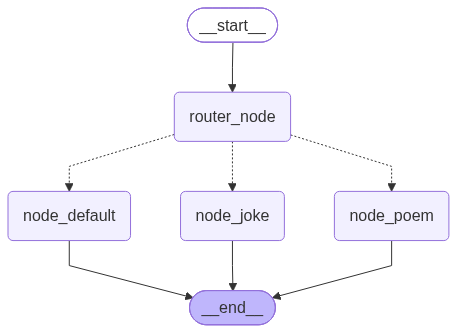

2026-10-17 23:43:17.923 | INFO     | __main__:router_node:44 - 路由节点已执行
2026-10-17 23:43:26.337 | INFO     | __main__:router_node:55 - 路由结果-res: {'mode': 'poem', 'topic': '布偶猫'}
2026-10-17 23:43:26.338 | INFO     | __main__:router:60 - 路由函数已执行
2026-10-17 23:43:26.339 | INFO     | __main__:router:62 - 路由至 node_poem 节点
2026-10-17 23:43:26.340 | INFO     | __main__:node_poem:72 - node_poem 已执行


{'username': '小黄', 'user_input': '帮我写一首关于布偶猫的七言绝句', 'output': '雪绒轻踏入春庭  \n蓝眸含月卧花阴  \n尾扫炉香惊蝶梦  \n慵眠不理世间音'}


In [ ]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class StructuredOutputState(TypedDict):
    mode: Literal["poem", "joke", "default"]
    topic: str

class OverAllState(TypedDict):
    username: str
    user_input: str
    output: str

# 创建专用于路由的结构化输出模型，不改变原来的 model
router_model = model.with_structured_output(
    StructuredOutputState,
    method="function_calling",
)


# 按照指定格式输出是这样吗?
def router_node(state: OverAllState) -> StructuredOutputState:
    logger.info("路由节点已执行")
    user_input = state["user_input"]
    res = router_model.invoke([
        SystemMessage(
            "你是任务分类器，只提取任务类型和主题，不要执行创作任务。"
            "要求写诗时 mode=poem，讲笑话时 mode=joke，"
            "其他任务 mode=default。"
            "topic 提取用户指定的主题，未指定时使用空字符串。"
        ),
        HumanMessage(state["user_input"]),
    ])
    logger.info("路由结果-res: {}", res)

    return res

def router(state: StructuredOutputState) -> Literal["node_poem", "node_joke", "node_default"]:
    logger.info("路由函数已执行")
    if state["mode"] == "poem":
        logger.info("路由至 node_poem 节点")
        return "node_poem"
    elif state["mode"] == "joke":
        logger.info("路由至 node_joke 节点")
        return "node_joke"

    logger.info("路由至兜底节点")
    return "node_default"

def node_poem(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句，不要赏析，只给诗句即可")]).content

    return {
        "output": poem
    }

def node_joke(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话，尽可能简单，不超过一百字")]).content

    return {
        "output": joke
    }

def node_default(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_default 已执行")

    return {
        "output": "无法处理的任务类型"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router_node", router_node)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_default", node_default)

builder.add_edge(START, "router_node")
builder.add_conditional_edges(
    "router_node",
    router,
    path_map=["node_poem", "node_joke", "node_default"]
)
builder.add_edge("node_poem", END)
builder.add_edge("node_joke", END)
builder.add_edge("node_default", END)

checkpointer = InMemorySaver()
config = {"configurable": {"thread_id": "123"}}
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

res = graph.invoke({
    "username": "小黄",
    "user_input": "帮我写一首关于布偶猫的七言绝句"
}, config=config)
print(res)

1.  获取历史检查点列表

In [8]:
history_checkpoints = list(graph.get_state_history(config=config))
rprint(history_checkpoints)

[
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'output': '雪绒轻踏入春庭  \n蓝眸含月卧花阴  \n尾扫炉香惊蝶梦  \n慵眠不理世间音',
            'mode': 'poem',
            'topic': '布偶猫'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-e299-60f8-8002-0da3d1a57a33'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-18T06:43:35.567171+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-8a99-6632-8001-ed223ac1d043'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'mode': 'poem',
            'topic': '布偶猫'
        },
        next=('node_poem',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-8a99-6632-8001-ed223ac1d043'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-18T06:43:26.339835+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
            }
        },
        tasks=(
            PregelTask(
                id='351dd43b-12e9-1e6d-7ea2-d4b0963dcc0b',
                name='node_poem',
                path=('__pregel_pull', 'node_poem'),
                error=None,
                interrupts=(),
                state=None,
                result={'output': '雪绒轻踏入春庭  \n蓝眸含月卧花阴  \n尾扫炉香惊蝶梦  \n慵眠不理世间音'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'username': '小黄', 'user_input': '帮我写一首关于布偶猫的七言绝句'},
        next=('router_node',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-18T06:43:17.922543+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a52-6278-bfff-c811f4c597fb'
            }
        },
        tasks=(
            PregelTask(
                id='27f6ff06-4154-539a-662c-a7fcc82b77e7',
                name='router_node',
                path=('__pregel_pull', 'router_node'),
                error=None,
                interrupts=(),
                state=None,
                result={'mode': 'poem', 'topic': '布偶猫'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a52-6278-bfff-c811f4c597fb'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-18T06:43:17.922056+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='68cba5a0-7e44-7e20-f415-303d5bff57ba',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={'username': '小黄', 'user_input': '帮我写一首关于布偶猫的七言绝句'}
            ),
        ),
        interrupts=()
    )
]

2. 获取 `router_node` 之前的检查点

In [9]:
before_router_checkpoint = next(h for h in history_checkpoints if h.next == ('router_node',))
rprint(before_router_checkpoint)

StateSnapshot(
    values={'username': '小黄', 'user_input': '帮我写一首关于布偶猫的七言绝句'},
    next=('router_node',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
        }
    },
    metadata={'source': 'loop', 'step': 0, 'parents': {}},
    created_at='2026-10-18T06:43:17.922543+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cabf3-3a52-6278-bfff-c811f4c597fb'
        }
    },
    tasks=(
        PregelTask(
            id='27f6ff06-4154-539a-662c-a7fcc82b77e7',
            name='router_node',
            path=('__pregel_pull', 'router_node'),
            error=None,
            interrupts=(),
            state=None,
            result={'mode': 'poem', 'topic': '布偶猫'}
        ),
    ),
    interrupts=()
)

从这个检查点分叉，本文采用两种方案（还可以有别的方案）：
1. 修改输入，让 **`router_node`** 重新执行。
2. 直接伪造 **`router_node`** 的输出，从而跳过 **`router_node`**。

##### 6.5.4.2.1 只改输入State

In [10]:
# graph 调用修改状态的函数
# 把这次状态更新视为 **`START`** 的输出。
change_input_config = graph.update_state(
    config=before_router_checkpoint.config,
    values={"user_input": "帮我写一个关于布偶猫的笑话"},
    as_node=START
)

# 重新运行
response = graph.invoke(None, change_input_config)
rprint(response)

2026-10-17 23:50:47.669 | INFO     | __main__:router_node:44 - 路由节点已执行
2026-10-17 23:51:28.017 | INFO     | __main__:router_node:55 - 路由结果-res: {'mode': 'joke', 'topic': '布偶猫'}
2026-10-17 23:51:28.019 | INFO     | __main__:router:60 - 路由函数已执行
2026-10-17 23:51:28.019 | INFO     | __main__:router:65 - 路由至 node_joke 节点
2026-10-17 23:51:28.022 | INFO     | __main__:node_joke:81 - node_joke 已执行


{
    'username': '小黄',
    'user_input': '帮我写一个关于布偶猫的笑话',
    'output': '布偶猫去面试，老板问它会什么。它说：“我最会配合，您说啥，我都躺平。”'
}

In [ ]:
# 不能直接使用change_input_config，因为change_input_config包含了检查点ID？
history_checkpoints = list(graph.get_state_history(config=config))
rprint(history_checkpoints)

[
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一个关于布偶猫的笑话',
            'output': '布偶猫去面试，老板问它会什么。它说：“我最会配合，您说啥，我都躺平。”',
            'mode': 'joke',
            'topic': '布偶猫'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac05-9d18-6422-8003-78280aec2a9a'
            }
        },
        metadata={'source': 'loop', 'step': 3, 'parents': {}},
        created_at='2026-10-18T06:51:31.463053+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac05-7c45-66aa-8002-f6651c14d0d3'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一个关于布偶猫的笑话',
            'mode': 'joke',
            'topic': '布偶猫'
        },
        next=('node_joke',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac05-7c45-66aa-8002-f6651c14d0d3'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-18T06:51:28.021251+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac03-fb70-67f6-8001-d79f27bbf106'
            }
        },
        tasks=(
            PregelTask(
                id='fe8a1e60-ded1-9d0f-c67f-9ce06965b976',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error=None,
                interrupts=(),
                state=None,
                result={'output': '布偶猫去面试，老板问它会什么。它说：“我最会配合，您说啥，我都躺平。”'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'username': '小黄', 'user_input': '帮我写一个关于布偶猫的笑话'},
        next=('router_node',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac03-fb70-67f6-8001-d79f27bbf106'
            }
        },
        metadata={'source': 'update', 'step': 1, 'parents': {}},
        created_at='2026-10-18T06:50:47.668726+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
            }
        },
        tasks=(
            PregelTask(
                id='a4c52700-8035-d59d-3d50-f7e45014d411',
                name='router_node',
                path=('__pregel_pull', 'router_node'),
                error=None,
                interrupts=(),
                state=None,
                result={'mode': 'joke', 'topic': '布偶猫'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'output': '雪绒轻踏入春庭  \n蓝眸含月卧花阴  \n尾扫炉香惊蝶梦  \n慵眠不理世间音',
            'mode': 'poem',
            'topic': '布偶猫'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-e299-60f8-8002-0da3d1a57a33'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-18T06:43:35.567171+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-8a99-6632-8001-ed223ac1d043'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
        

##### 6.5.4.2.2 改状态且跳过某些节点

如果不希望重新执行 **`router_node`**，而是直接指定 **`router_node`** 的输出，可以把 **`as_node`** 设置为 **`"router_node"`**。

**示例如下**

```python
skip_router_config = graph.update_state(
    config=before_router_checkpoint.config,
    values={"topic": "狸花猫", "mode": "笑话"},
    as_node="router_node"
)
```

In [21]:
skip_router_config = graph.update_state(
    config=before_router_checkpoint.config,
    values={"topic": "狸花猫", "mode": "joke"},
    as_node="router_node"
)
rprint(skip_router_config)

2026-10-18 00:10:53.727 | INFO     | __main__:router:60 - 路由函数已执行
2026-10-18 00:10:53.728 | INFO     | __main__:router:65 - 路由至 node_joke 节点


{
    'configurable': {
        'thread_id': '123',
        'checkpoint_ns': '',
        'checkpoint_id': '1f1cac30-e956-65d4-8001-932ef1b45d9b'
    }
}

In [22]:
rprint(graph.get_state(skip_router_config))

StateSnapshot(
    values={
        'username': '小黄',
        'user_input': '帮我写一首关于布偶猫的七言绝句',
        'mode': 'joke',
        'topic': '狸花猫'
    },
    next=('node_joke',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cac30-e956-65d4-8001-932ef1b45d9b'
        }
    },
    metadata={'source': 'update', 'step': 1, 'parents': {}},
    created_at='2026-10-18T07:10:53.730135+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
        }
    },
    tasks=(
        PregelTask(
            id='5b89f1c1-c6f0-f1ac-b70e-39944eab4768',
            name='node_joke',
            path=('__pregel_pull', 'node_joke'),
            error=None,
            interrupts=(),
            state=None,
            result=None
        ),
    ),
    interrupts=()
)

In [23]:
response = graph.invoke(None, skip_router_config)

rprint(response)

2026-10-18 00:12:05.215 | INFO     | __main__:node_joke:81 - node_joke 已执行


{
    'username': '小黄',
    'user_input': '帮我写一首关于布偶猫的七言绝句',
    'output': '狸花猫问主人：“我抓到老鼠了，有奖励吗？”  \n主人说：“有，今晚你睡床上。”  \n狸花猫：“那老鼠呢？”  
\n主人：“也睡床上。”  \n狸花猫：“算了，我再抓一只。”'
}

In [24]:
# 不能直接使用change_input_config，因为change_input_config包含了检查点ID？
history_checkpoints = list(graph.get_state_history(config=config))
rprint(history_checkpoints)

[
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'output': '狸花猫问主人：“我抓到老鼠了，有奖励吗？”  \n主人说：“有，今晚你睡床上。”  
\n狸花猫：“那老鼠呢？”  \n主人：“也睡床上。”  \n狸花猫：“算了，我再抓一只。”',
            'mode': 'joke',
            'topic': '狸花猫'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac33-bbb7-60ee-8002-2a75aaf82d18'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-18T07:12:09.476917+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac30-e956-65d4-8001-932ef1b45d9b'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'mode': 'joke',
            'topic': '狸花猫'
        },
        next=('node_joke',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac30-e956-65d4-8001-932ef1b45d9b'
            }
        },
        metadata={'source': 'update', 'step': 1, 'parents': {}},
        created_at='2026-10-18T07:10:53.730135+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
            }
        },
        tasks=(
            PregelTask(
                id='5b89f1c1-c6f0-f1ac-b70e-39944eab4768',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'output': '狸花猫问主人：“我抓到老鼠了，有奖励吗？”  \n主人说：“有，今晚你睡床上。”  
\n狸花猫：“那老鼠呢？”  \n主人：“也睡床上。”  \n狸花猫：“算了，我再抓一只。”'
                }
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'mode': 'joke',
            'topic': '狸花猫'
        },
        next=('node_joke',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac30-d9c2-60f0-8001-a6d0947ceb6d'
            }
        },
        metadata={'source': 'update', 'step': 1, 'parents': {}},
        created_at='2026-10-18T07:10:52.096529+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cabf3-3a53-659c-8000-921304ef3a30'
            }
        },
        tasks=(
            PregelTask(
                id='0db41224-a8c8-6400-561b-92e346306040',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error=None,
                interrupts=(),
                state=None,
                result=None
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '小黄',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'mode': '笑话',
            'topic': '狸花猫'
        },
        next=('node_default',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cac2e-8a15-6a9a-8001-6d96956f576c'
            }
        },
        metadata={'source': 'update', 'step': 1, 'parents': {}},
        created_at='2026-10-18T07:09:50.055076+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_i

这种方式常用于测试场景。例如：

* 跳过不稳定的大模型路由节点。
* 手动指定路由结果，测试不同分支。
* 修改历史状态，验证后续节点能否正常运行。
* 基于同一个历史检查点探索多条可能的执行路径。

不过在正式业务流程中，应谨慎使用这种方式。因为它是在伪造某个节点的输出，如果伪造的状态不符合后续节点的预期，可能导致逻辑混乱，甚至抛出运行时异常。

# 总结

1. 通过graph.update_state() 更新某个检查点的状态。
2. 更新后分为 Retry 和 fork 两种方式
3. 如果是从某个检查点重新运行，需要 `invoke(none,config)`

# 问题

### 1. 修改状态后，原来 graph 的状态列表是怎么变化的？

**`update_state()` 会基于指定检查点创建新检查点，旧状态和原执行分支仍然保留；继续运行又会生成后续检查点。** 因此，历史列表中的 `StateSnapshot` 数量会增加。这些是不同时间、不同分支的状态快照，不是 State 字段变多了。

**为什么原来的 `config` 也能查到新分支？**

原 `config` 只有 `thread_id="123"`，没有指定 `checkpoint_id`。两种 Fork 都沿用这个 thread，因此 `graph.get_state_history(config)` 会列出该 thread、当前命名空间下所有分支的检查点，按新到旧排列。`update_state()` 返回新的配置，不会把原 `config` 改成某条分支的专属配置；读取历史本身也不会创建检查点。

**本例的数量变化：**

| 操作 | 新增检查点 | 总数 |
| --- | --- | --- |
| 首次执行写诗流程 | 输入检查点、START 后、路由节点后、写诗节点后，共 4 个 | 4 |
| 修改输入，`as_node=START` | `update_state()` 创建 1 个；重新执行路由节点和笑话节点各创建 1 个 | 7 |
| 伪造路由输出，`as_node="router_node"` | `update_state()` 创建 1 个；执行笑话节点再创建 1 个 | 9（每种 Fork 各执行一次时） |

用简写表示检查点关系，箭头表示父检查点指向子检查点：

```text
输入检查点 → A：START 后，下一步 router_node
              ├─ B：原路由结果 poem → C：原诗歌结果
              ├─ D：修改输入（update）→ E：新路由结果 joke → F：布偶猫笑话
              └─ G：伪造路由结果（update）→ H：狸花猫笑话
```

D、G 的父检查点都是 A；分叉没有覆盖 B、C，也没有复制 A 之前的全部历史。`as_node="router_node"` 会应用该节点的写入逻辑并计算条件分支，但不会执行路由节点本身，因此比第一种方案少生成一个检查点。

**为什么 Notebook 最后实际显示 12 个，而不是 9 个？**

最后的输出还包含 3 个额外的 `source="update"` 检查点，ID 分别以 `1f1cac2b-9aea`、`1f1cac2e-8a15`、`1f1cac30-d9c2` 开头。它们的父检查点都是 A，说明内核中还发生过 3 次额外状态更新，例如修改代码后重复执行了 `update_state()`。即使参数相同、或者创建分支后没有继续运行，也会保留新的检查点。所以本次实际为 **4 + 3 + 2 + 3 = 12 个**。

历史列表只是将这棵分支树按创建顺序倒序展示；不能把相邻列表项都当作父子关系。应查看 **`parent_config`** 确认父节点，`metadata["step"]` 在不同分支上可以重复。

另外，带 `checkpoint_id` 的配置也可以传给 `get_state_history()`：当前使用的 `InMemorySaver` 会按该 ID 精确筛选，通常只返回那一个快照，不会自动查询该分支的完整历史。要查看某条分支的祖先链，可从终点开始反复用 `graph.get_state(snapshot.parent_config)` 向前追溯。

参考：[LangGraph Fork 机制](https://docs.langchain.com/oss/python/langgraph/use-time-travel#fork)。